Backward written manually

## Preparation

In [1]:
import torch
import math
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

# read file
words = open('names.txt', 'r').read().splitlines()
words[:10]

# mapping from letters to numbers and reverse
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos) # 27

# turning the dataset into the structure of [input] [desired output]
block_size = 3 
X, Y = [], []
for word in words:
    context = [0] * block_size 
    for ch in word + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix] 
X = torch.tensor(X) 
Y = torch.tensor(Y) 

# split the dataset (tr/dev/ts) (80/10/10)
def build_dataset(words):
    block_size = 3
    X, Y = [], [] 
    for word in words:
        # print(word)
        context = [0] * block_size 
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '------>', itos[ix])
            context = context[1:] + [ix] 
    X = torch.tensor(X) 
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1]) # 80%
Xdev, Ydev = build_dataset(words[n1: n2]) # 10%
Xts, Yts = build_dataset(words[n2:]) # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


## new things

In [2]:
# utility function used to compare manual gradient to PyTorch gradients
def cmp(s, dt, t):
    ex = torch.all(dt == t.grad).item() # dt is the grad we calculate
    # exact equality
    app = torch.allclose(dt, t.grad) # return if all elements match within acceptable margins
    # approximate equality
    # |inputi - otheri| < absolute_tolerance + relative_tolerance * |otheri|
    maxdiff = (dt - t.grad).abs().max().item()
    print(f'{s:15s} | {str(ex):5s} | approximate: {str(app):5s} | maxdiff: {maxdiff}')

What we had

```
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) * 5/3 * (1/(n_embd * block_size)**0.5)
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * (1/(n_hidden)**0.5)
b2 = torch.zeros(vocab_size)


bngain = torch.ones(1, n_hidden) 
bnbias = torch.zeros(1, n_hidden) 
# ------------- changed
bnmean_running = torch.zeros(1, n_hidden) 
# we can set it to one since the hpreact distribution should be Gaussian upon initialization
bnstd_running = torch.ones(1, n_hidden)
# same thing above
# ------------- changed

parameters = [C, W1, W2, b2, bngain, bnbias]
print(sum([parameter.nelement() for parameter in parameters]))
for parameter in parameters:
    parameter.requires_grad = True
```

We make a few changes on bngain and bnbias since initializing with all ones or all zeros mask an incorrect implementation of backward pass. 

We will also use b1 also it is useless because fo the normalization afterwards, just to check whether the code works well and gives zero for those entries of b1. 

In [3]:
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 64 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),               generator = g)
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) * 5/3 * (1/(n_embd * block_size)**0.5)
b1 = torch.randn(n_hidden,                          generator = g) * 0.1 # added back though useless
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * (1/(n_hidden)**0.5)
b2 = torch.randn(vocab_size,                        generator = g) * 0.1 # changed

bngain = torch.randn((1, n_hidden)) * 0.1 + 1.0 # changed
bnbias = torch.randn((1, n_hidden)) * 0.1 # changed

bnmean_running = torch.zeros(1, n_hidden) 
bnstd_running = torch.ones(1, n_hidden)

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum([parameter.nelement() for parameter in parameters]))
for parameter in parameters:
    parameter.requires_grad = True

4137


The actual implementation of the traeinig loop hs also expanded a lot because the steps are broken into smaller pieces instead of a pytorch function that combines everything toether like cross_entropy. 

This breaking down helps us see the exact steps we need in the back propogation part. 

In [4]:
batch_size = 32
n = batch_size # a shorter expression for convenience of calculation
# construction of minibatch
ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator = g)
Xb, Yb = Xtr[ix], Ytr[ix]

### 1. Compute the Variance ($\sigma^2$)
$$ \sigma^2 = \frac{1}{m-1} \sum_{i=1}^{m} (x_i - \mu)^2 $$

### 2. Apply Normalization (with $\epsilon$)
$$ x' = \frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}} $$

### 1. Normalization (Min-Max Scaling)
$$X_{norm} = \frac{X - X_{min}}{X_{max} - X_{min}}$$

### 2. Standardization (Z-Score)
$$X_{std} = \frac{X - \mu}{\sigma}$$

**Where:**
* $X$ is the original data point.
* $X_{min}$ and $X_{max}$ are the minimum and maximum values of the feature.
* $\mu$ is the mean of the feature.
* $\sigma$ is the standard deviation of the feature.


In [19]:
eps = 1e-5
# forward pass, chunkated into smaller steps that are possible to backward one at a time

emb = C[Xb] # embedding characters into vectors
embcat = emb.view(Xb.shape[0], -1) # concatenating the vectors
# linear layer 1
hprebn = embcat @ W1 + b1 # hidden layer preactivation
# batchnorm layer
bnmeani = 1/n * hprebn.sum(0, keepdims=True)
bndiff = hprebn - bnmeani
bndiff_sq = bndiff**2
bnvar = 1/(n-1) * bndiff_sq.sum(0, keepdims=True) # bessel's correction
bnvar_inv = (bnvar + eps) ** -0.5
bnraw = bndiff * bnvar_inv
hpreact = bngain * bnraw + bnbias
# nonlinearity
h = torch.tanh(hpreact)
# lienar layer 2
logits = h @ W2 + b2
# cross_entropy loss
logits_maxes = logits.max(1, keepdims=True).values  # pytorch max return both values and indices
norm_logits = logits - logits_maxes # submax for numerical stability (of it is positively high it may end up in inf)
counts = norm_logits.exp()
counts_sum = counts.sum(1, keepdims=True)
counts_sum_inv = counts_sum ** -1 # (division 1/counts_sum cannot get exact grad)
probs = counts * counts_sum_inv
# calculating loss function
logprobs = probs.log()
loss = -logprobs[range(n), Yb].mean()

# pytorch.backward pass
for p in parameters:
    p.grad = None
for t in [logprobs, probs, counts, counts_sum, counts_sum_inv, 
          norm_logits, logits_maxes, logits, h, hpreact, bnraw,
          bnvar_inv, bnvar, bndiff_sq, bndiff, hprebn, bnmeani,
          embcat, emb, C]:
    t.retain_grad()
loss.backward()
loss


tensor(3.3876, grad_fn=<NegBackward0>)

In [30]:
hpreact.shape, hprebn.shape

(torch.Size([32, 64]), torch.Size([32, 64]))

In [21]:
# exercise 1: backprop through the whole thing manually
# backpropogation through exactly all of the variables
# as they are defined in the word pass above, one by one

dlogprobs = torch.zeros(logprobs.shape)
dlogprobs[range(n), Yb] = -1.0/n
cmp('logprobs', dlogprobs, logprobs)

# dprobs = torch.zeros(probs.shape)
# dprobs[range(n), Yb] = (probs.data[range(n), Yb]**-1) * dlogprobs[range(n), Yb]
dprobs = 1/probs * dlogprobs # taking those predictions with low probalities and boost their gradient
cmp('probs', dprobs, probs)

dcounts_sum_inv = (counts * dprobs).sum(1, keepdims=True)
dcounts = counts_sum_inv * dprobs # there is another contribution to dcounts
cmp('counts_sum_inv', dcounts_sum_inv, counts_sum_inv)

dcounts_sum = -(counts_sum)**-2 * dcounts_sum_inv
cmp('counts_sum', dcounts_sum, counts_sum)

dcounts += torch.ones(counts.shape) * dcounts_sum
cmp('counts', dcounts, counts)

dnorm_logits = counts * dcounts
cmp('norm_logits', dnorm_logits, norm_logits)

# dlogits = torch.ones(logits.shape) * dnorm_logits
dlogits = dnorm_logits.clone()
# dlogits_maxes = (-torch.ones(logits.shape) * dnorm_logits).sum(1, keepdims=True)
dlogits_maxes = -dnorm_logits.sum(1, keepdims=True)
cmp('logits_maxes', dlogits_maxes, logits_maxes)

dlogits += F.one_hot(logits.max(1).indices, num_classes = vocab_size) * dlogits_maxes
# one-hot encoding
cmp('logits', dlogits, logits)

db2 = dlogits.sum(0, keepdims=True)
dh = dlogits @ W2.T
dW2 = h.T @ dlogits
cmp('b2', db2, b2)
cmp('h', dh, h)
cmp('W2', dW2, W2)

dhpreact = (1 - h**2) * dh
cmp('hpreact', dhpreact, hpreact)

dbnbias = dhpreact.sum(0, keepdims=True)
dbngain = (bnraw * dhpreact).sum(0, keepdims=True)
dbnraw = dhpreact * bngain
cmp('bnbias', dbnbias, bnbias)
cmp('bngain', dbngain, bngain)
cmp('bnraw', dbnraw, bnraw)

dbndiff = dbnraw * bnvar_inv
dbnvar_inv = (dbnraw * bndiff).sum(0, keepdims = True)
cmp('bnvar_inv', dbnvar_inv, bnvar_inv)

dbnvar = -0.5 * (bnvar + 1e-5)**-1.5 * dbnvar_inv
cmp('bnvar', dbnvar, bnvar)

dbndiff_sq = 1/(n-1) * torch.ones(bndiff_sq.shape) * dbnvar
# (1.0/(n-1)) * torhc.ones_like(bndiff_sq) * dbnvar
cmp('bndiff_sq', dbndiff_sq, bndiff_sq)

dbndiff += 2 * bndiff * dbndiff_sq
cmp('bndiff', dbndiff, bndiff)

dhprebn = dbndiff.clone()
dbnmeani = -dbndiff.sum(0, keepdims = True)
cmp('bnmeani', dbnmeani, bnmeani)

dhprebn += 1/n * torch.ones(dhprebn.shape) * dbnmeani
# 1/N * torch.ones_like(dhprebn) * dbnmeani
cmp('hprebn', dhprebn, hprebn)

dembcat = dhprebn @ W1.T
dW1 = embcat.T @ dhprebn
db1 = dhprebn.sum(0)
cmp('embcat', dembcat, embcat)
cmp('W1', dW1, W1)
cmp('b1', db1, b1)

demb = dembcat.view(emb.shape)
# demb = dembcat.view(n, block_size, n_embd)
cmp('emb', demb, emb)

dC = torch.zeros_like(C)
for k in range(Xb.shape[0]):
    for j in range(Xb.shape[1]):
        ix = Xb[k,j]
        dC[ix] += demb[k,j]
cmp('C', dC, C)


logprobs        | True  | approximate: True  | maxdiff: 0.0
probs           | True  | approximate: True  | maxdiff: 0.0
counts_sum_inv  | True  | approximate: True  | maxdiff: 0.0
counts_sum      | True  | approximate: True  | maxdiff: 0.0
counts          | True  | approximate: True  | maxdiff: 0.0
norm_logits     | True  | approximate: True  | maxdiff: 0.0
logits_maxes    | True  | approximate: True  | maxdiff: 0.0
logits          | True  | approximate: True  | maxdiff: 0.0
b2              | True  | approximate: True  | maxdiff: 0.0
h               | True  | approximate: True  | maxdiff: 0.0
W2              | True  | approximate: True  | maxdiff: 0.0
hpreact         | True  | approximate: True  | maxdiff: 0.0
bnbias          | True  | approximate: True  | maxdiff: 0.0
bngain          | True  | approximate: True  | maxdiff: 0.0
bnraw           | True  | approximate: True  | maxdiff: 0.0
bnvar_inv       | True  | approximate: True  | maxdiff: 0.0
bnvar           | True  | approximate: T

In [23]:
# exercise 2: backprop through cross_entropy but all in one go
# to complete this exercise look at the mathematical expression of the loss
# take the derivative, simplify the expression, and write it out

# now
loss_fast = F.cross_entropy(logits, Yb)
print(loss_fast.item(), 'diff: ', (loss_fast - loss).item())

dlogits = F.softmax(logits, 1)
dlogits[range(n), Yb] -= 1
dlogits /= n

cmp('logits', dlogits, logits)

3.3875582218170166 diff:  2.384185791015625e-07
logits          | False | approximate: True  | maxdiff: 4.889443516731262e-09


In [24]:
F.softmax(logits, 1)[0]

tensor([0.0687, 0.1080, 0.0164, 0.0535, 0.0164, 0.0909, 0.0231, 0.0328, 0.0162,
        0.0265, 0.0360, 0.0320, 0.0336, 0.0258, 0.0332, 0.0103, 0.0067, 0.0163,
        0.0141, 0.0628, 0.0481, 0.0166, 0.0188, 0.0877, 0.0663, 0.0220, 0.0170],
       grad_fn=<SelectBackward0>)

In [25]:
dlogits[0] * n

tensor([ 0.0687,  0.1080,  0.0164,  0.0535,  0.0164,  0.0909,  0.0231,  0.0328,
        -0.9838,  0.0265,  0.0360,  0.0320,  0.0336,  0.0258,  0.0332,  0.0103,
         0.0067,  0.0163,  0.0141,  0.0628,  0.0481,  0.0166,  0.0188,  0.0877,
         0.0663,  0.0220,  0.0170], grad_fn=<MulBackward0>)

In other words we are trying to pull down the probablities of the incorrect characters and pull up the probablities of the correct character. And the exact total amount of pull is equal since the sum is 0 basically. 

In [26]:
dlogits[0].sum()

tensor(4.6566e-10, grad_fn=<SumBackward0>)

In [31]:
# forward pass with batch normalization
# ------------------ before
# bnmeani = 1/n * hprebn.sum(0, keepdims=True)
# bndiff = hprebn - bnmeani
# bndiff_sq = bndiff**2
# bnvar = 1/(n-1) * bndiff_sq.sum(0, keepdims=True) # bessel's correction
# bnvar_inv = (bnvar + eps) ** -0.5
# bnraw = bndiff * bnvar_inv
# hpreact = bngain * bnraw + bnbias
# ------------------ before

dhprebn = bngain * bnvar_inv / n * (n * dhpreact - dhpreact.sum(0) - n / (n-1) * bnraw * (dhpreact * bnraw).sum(0))
cmp('hprebn', dhprebn, hprebn)

# now
hpreact_fast = bngain * (hprebn - hprebn.mean(0, keepdims=True)) / torch.sqrt(hprebn.var(0, keepdims=True, unbiased=True)+eps) + bnbias
print('max diff: ', (hpreact_fast - hpreact).abs().max())

hprebn          | False | approximate: True  | maxdiff: 1.862645149230957e-09
max diff:  tensor(4.7684e-07, grad_fn=<MaxBackward1>)


12297
      1/ 200000: 3.5363
  10000/ 200000: 2.3438
  20000/ 200000: 1.6108
  30000/ 200000: 2.2437
  40000/ 200000: 2.4134
  50000/ 200000: 2.4991
  60000/ 200000: 1.7626
  70000/ 200000: 1.9313
  80000/ 200000: 2.1693
  90000/ 200000: 2.2842
 100000/ 200000: 2.0622
 110000/ 200000: 2.0824
 120000/ 200000: 2.1104
 130000/ 200000: 2.2300
 140000/ 200000: 1.9314
 150000/ 200000: 2.5056
 160000/ 200000: 2.0471
 170000/ 200000: 1.6653
 180000/ 200000: 1.7276
 190000/ 200000: 2.1248
 200000/ 200000: 2.3072


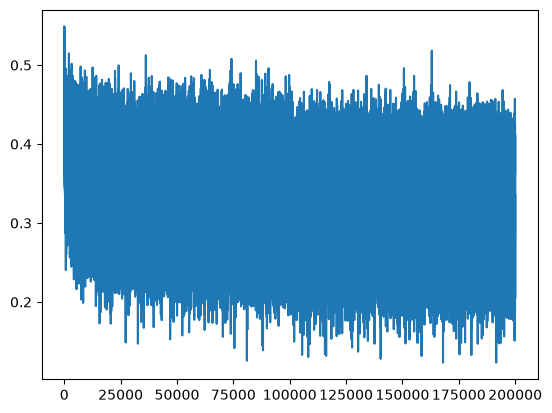

In [62]:
# put it all together
n_embd = 10 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embd),               generator = g)
# Layer 1
W1 = torch.randn((n_embd * block_size, n_hidden),   generator = g) * 5/3 * (1/(n_embd * block_size)**0.5)
b1 = torch.randn(n_hidden,                          generator = g) * 0.1 # added back though useless
# Layer 2
W2 = torch.randn((n_hidden, vocab_size),            generator = g) * (1/(n_hidden)**0.5)
b2 = torch.randn(vocab_size,                        generator = g) * 0.1 # changed
# batchnorm parameters
bngain = torch.randn((1, n_hidden)) * 0.1 + 1.0 # changed
bnbias = torch.randn((1, n_hidden)) * 0.1 # changed

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum([parameter.nelement() for parameter in parameters]))
for parameter in parameters:
    parameter.requires_grad = True

# optimization as last time
max_steps = 200000
batch_size = 32
lossi = []
eps = 1e-5
n = batch_size # a shorter expression for convenience of calculation

# telling pytorch not to do backprop itself
with torch.no_grad():
    for i in range(max_steps):

        # construction of minibatch
        ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator = g)
        Xb, Yb = Xtr[ix], Ytr[ix]

        # forward pass, chunkated into smaller steps that are possible to backward one at a time
        emb = C[Xb] # embedding characters into vectors
        embcat = emb.view(Xb.shape[0], -1) # concatenating the vectors
        # ---------------- linear layer 1
        hprebn = embcat @ W1 + b1 # hidden layer preactivation
        # ---------------- batchnorm layer
        bnmeani = 1/n * hprebn.sum(0, keepdims=True)
        bnvar = hprebn.var(0, keepdims=True, unbiased=True) # bessel's correction
        bnvar_inv = (bnvar + eps) ** -0.5
        bnraw = (hprebn - bnmeani) * bnvar_inv
        hpreact = bngain * bnraw + bnbias
        # ---------------- nonlinearity
        h = torch.tanh(hpreact)
        # linear layer 2
        logits = h @ W2 + b2
        loss = F.cross_entropy(logits,Yb) # loss function

        # pytorch.backward pass
        for p in parameters:
            p.grad = None
        # loss.backward()

        # manual backprop
        dlogits = F.softmax(logits, 1)
        dlogits[range(n), Yb] -= 1
        dlogits /= n
        # one-hot encoding
        db2 = dlogits.sum(0)
        dh = dlogits @ W2.T
        dW2 = h.T @ dlogits
        dhpreact = (1.0 - h**2) * dh
        dbngain = (bnraw * dhpreact).sum(0, keepdims=True)
        dbnbias = dhpreact.sum(0, keepdims=True)
        dhprebn = bngain * bnvar_inv / n * (n * dhpreact - dhpreact.sum(0) - n / (n-1) * bnraw * (dhpreact * bnraw).sum(0))
        # 1/N * torch.ones_like(dhprebn) * dbnmeani
        dembcat = dhprebn @ W1.T
        dW1 = embcat.T @ dhprebn
        db1 = dhprebn.sum(0)
        demb = dembcat.view(emb.shape)
        # demb = dembcat.view(n, block_size, n_embd)
        dC = torch.zeros_like(C)
        for k in range(Xb.shape[0]):
            for j in range(Xb.shape[1]):
                ix = Xb[k,j]
                dC[ix] += demb[k,j]
        grads = [dC, dW1, db1, dW2, db2, dbngain, dbnbias]

        # update
        lr = 0.1 if i < 100000 else 0.01
        for p, grad in zip(parameters, grads):
            # p.data -= lr * p.grad
            p.data -= lr * grad
        # for parameter in parameters:
        #     parameter.data -= lr * parameter.grad

        # tract stats:
        if i == 0:
            print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
        if (i+1) % 10000 == 0:
            print(f"{i+1:7d}/{max_steps:7d}: {loss.item():.4f}")
        lossi.append(loss.log10().item())
        
        # if i == 100:
        #     break

# plot the loss over time
plt.plot(lossi)

In [60]:
for p, g in zip(parameters, grads):
    cmp(str(tuple(p.shape)), g, p)

(27, 10)        | False | approximate: True  | maxdiff: 8.381903171539307e-09
(30, 200)       | False | approximate: True  | maxdiff: 7.450580596923828e-09
(200,)          | False | approximate: True  | maxdiff: 2.9103830456733704e-09
(200, 27)       | False | approximate: True  | maxdiff: 1.4901161193847656e-08
(27,)           | False | approximate: True  | maxdiff: 3.725290298461914e-09
(1, 200)        | False | approximate: True  | maxdiff: 2.3283064365386963e-09
(1, 200)        | False | approximate: True  | maxdiff: 3.725290298461914e-09


In [65]:
with torch.no_grad():
    emb = C[Xtr]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 + b1
    bnmean = hpreact.mean(0, keepdims = True) 
    bnstd = hpreact.std(0, keepdims = True)
print(bnmean)
print(bnstd)


tensor([[-2.8490e+00,  9.0488e-01, -1.1288e+00,  1.0438e+00,  1.6518e+00,
          1.0412e+00,  2.7066e+00, -3.2759e+00,  2.3934e-01,  1.5733e+00,
         -1.8576e+00, -1.4366e+00, -1.8345e-01,  2.2285e-01, -1.4206e+00,
         -1.5205e-01,  2.1267e+00, -2.9255e+00, -7.8759e-01,  2.0597e+00,
          3.2935e-02, -1.9227e-01,  1.0003e+00,  9.9331e-01,  1.5528e+00,
         -2.3252e-01,  1.9399e+00,  1.2112e+00, -1.2723e-01,  2.4173e+00,
         -1.1314e-01, -1.5638e+00,  8.6044e-02,  4.6576e-01, -7.1808e-01,
         -1.1389e+00, -5.7520e-01,  1.0005e+00, -2.0783e-01,  9.3444e-01,
         -1.3044e+00, -9.3519e-01, -4.7172e-01, -8.9430e-01,  1.1098e+00,
          2.3535e-01,  9.2043e-01, -1.3181e+00,  2.5761e+00,  1.6339e+00,
         -7.5217e-02,  1.9875e-01,  2.5502e+00,  4.8944e-01,  6.9553e-01,
         -1.9024e+00,  1.0099e-01,  1.1306e+00,  1.8415e+00, -2.0264e+00,
         -5.8192e-01, -9.9877e-02,  1.1138e+00, -7.9978e-01,  2.2201e+00,
          8.7721e-01,  1.0575e+00,  1.

In [66]:
@torch.no_grad() # this decorator disables gradient tracking

def split_loss(split): # split is either train, val, or test
    x, y = {
        'train': [Xtr, Ytr],
        'val': [Xdev, Ydev],
        'test': [Xts, Yts],
    }[split]
    emb = C[x] # (N, block_size, n_embd)
    embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
    hpreact = embcat @ W1 + b1
    # hpreact = bngain * (hpreact - hpreact.mean(0, keepdims=True))/hpreact.std(0, keepdims=True) + bnbias
    # we use the mean and sd created above to calculate the same thing
    hpreact = bngain * (hpreact - bnmean)/bnstd + bnbias
    h = torch.tanh(hpreact) # (N, n_hidden)
    logits = h @ W2 + b2 # (N, voacb_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.0705926418304443
val 2.1095497608184814


In [64]:
# sample from the model

g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        emb = C[torch.tensor([context])]
        embcat = emb.view(emb.shape[0], -1)
        hpreact = embcat @ W1 + b1
        hpreact = bngain * (hpreact - bnmeani) * (bnvar + 1e-5) ** 0.5 + bnbias
        h = torch.tanh(hpreact)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1) # take exponents and then normalizing
        ix = torch.multinomial(probs, num_samples = 1, generator = g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break
    print(''.join(itos[ix] for ix in out))


cathanzqueshawn.
kwell.
gentlissa.
stacjuxtnewfagdrystinaquigh.
kenza.
christon.
gengdulliopeck.
quintzn.
ziverlynn.
quisteffrojarystiff.
gurdusluwe.
ceciiah.
takley.
frandrae.
bryx.
ksya.
prago.
brenzley.
marcaidonnah.
fatdlius.
